# 实验 01 · 代价函数与梯度下降

目标：把损失、梯度与参数更新连起来，观察学习率的影响。

本实验为新增练习，仅依赖 NumPy；题干、测试均不包含参考实现。
从上到下执行，完成每个 TODO 后运行对应自测。

In [1]:
import numpy as np
rng = np.random.default_rng(42)

## 1 · 单变量回归的代价与梯度

实现 cost_and_gradient(x,y,w,b)，返回 (J,dw,db)，J 使用课程约定的平方误差和除以 2m。支持一维数组。

In [7]:
def cost_and_gradient(x, y, w, b):

    yhat = w*x + b
    return np.mean((yhat-y)**2)/2, np.mean((yhat-y)*x), np.mean(yhat-y)

    raise NotImplementedError("TODO: 代价与梯度")

In [8]:
x = np.array([1., 2., 3.]); y = np.array([3., 5., 7.])
np.testing.assert_allclose(cost_and_gradient(x, y, 2., 1.), [0., 0., 0.])
J, dw, db = cost_and_gradient(x, y, 0., 0.)
np.testing.assert_allclose([J, dw, db], [83 / 6, -34 / 3, -5.])
eps = 1e-6
numeric_dw = (cost_and_gradient(x, y, 0.3 + eps, -0.2)[0] - cost_and_gradient(x, y, 0.3 - eps, -0.2)[0]) / (2 * eps)
numeric_db = (cost_and_gradient(x, y, 0.3, -0.2 + eps)[0] - cost_and_gradient(x, y, 0.3, -0.2 - eps)[0]) / (2 * eps)
np.testing.assert_allclose(cost_and_gradient(x, y, 0.3, -0.2)[1:], [numeric_dw, numeric_db], rtol=1e-6)
print("通过：已知值、有限差分梯度检查")

通过：已知值、有限差分梯度检查


## 2 · 参数更新与收敛

实现 train_linear(x,y,w,b,alpha,steps)。调用上一题函数，使用同一步的梯度同时更新 w、b。返回最终 w、b 和长度 steps+1 的损失记录，首项为更新前损失。

In [10]:
def train_linear(x, y, w, b, alpha, steps):

    J, dw, db = cost_and_gradient(x, y, w, b)
    history = [J]
    for _ in range(steps):
        w = w-alpha*dw
        b = b-alpha*db
        J, dw, db = cost_and_gradient(x, y, w, b)
        history.append(J)

    return w, b, history

In [11]:
x = np.array([1., 2., 3.]); y = np.array([3., 5., 7.])
w, b, history = train_linear(x, y, 0., 0., 0.05, 2000)
assert len(history) == 2001
np.testing.assert_allclose(history[0], 83 / 6)
np.testing.assert_allclose([w, b], [2., 1.], atol=1e-4)
np.testing.assert_allclose(history[-1], cost_and_gradient(x, y, w, b)[0])
assert np.all(np.diff(history) <= 1e-10)
w0, b0, h0 = train_linear(x, y, 0.2, 0.3, 0.05, 0)
np.testing.assert_allclose([w0, b0], [0.2, 0.3]); assert len(h0) == 1
print("通过：损失记录、收敛、零步边界")

通过：损失记录、收敛、零步边界


## 3 · 学习率实验

用 alpha=0.001、0.05、0.5 分别运行 100 步，画出损失曲线。运行前先预测哪种情况最慢、哪种可能发散；不要求所有曲线都下降。

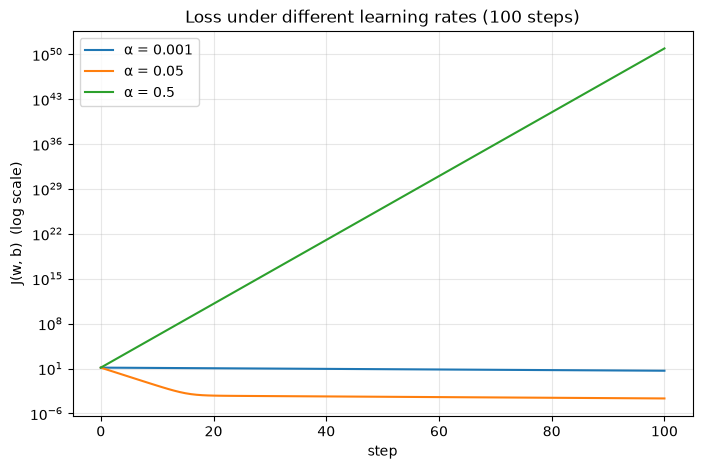

In [12]:
# TODO: 创建至少三组实验并画图；可使用 matplotlib。

import matplotlib.pyplot as plt

x = np.array([1., 2., 3.])
y = np.array([3., 5., 7.])

alphas = [0.001, 0.05, 0.5]
plt.figure(figsize=(8, 5))
for alpha in alphas:
    w, b, history = train_linear(x, y, 0., 0., alpha, 100)
    plt.plot(history, label=f"α = {alpha}")

plt.yscale("log")
plt.xlabel("step")
plt.ylabel("J(w, b)  (log scale)")
plt.title("Loss under different learning rates (100 steps)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

# raise NotImplementedError("TODO: 学习率实验")

In [ ]:
# 此题为开放实验：请在最后的实验记录中解释观察，不能仅粘贴图。

## 实验记录

写出输入/输出形状，解释一个边界情况，再记录一次修改参数前后的观察。

`x, y` 为一维 `(m,)`；`w, b` 标量；`history` 一维 `(steps+1,)`。`cost_and_gradient` 返回 `(标量, 标量, 标量)`（即 `dw, db` 已对 m 求平均，而非保留 `(m,)`）。

`steps = 0` 时循环不执行，`history` 长度 1、值等于初始损失；`w, b` 未被修改——这是"零步训练不应改变参数"的语义。

把 $\alpha$ 从 `0.05` 改为 `0.5`，其它不变，最终损失从 ~0 变为巨大正值；改回 `0.05` 或 `α=0.001` 则损失单调下降，只是后者下降幅度在图中几乎是水平的直线，印证了"学习率过小收敛慢、过大发散"的结论。